# 2. Does an optimism bias evolve, alone and in social dilemmas?
I evolve the learning rates (α⁺, α⁻) in populations of 100 agents over 150 generations.
Each generation, agents live one lifetime, the highest earners are more likely to reproduce,
and offspring inherit their parent's learning rates with small mutations.

* **Replication (individual learning):** agents learn a 2-armed bandit alone, as in
  Hoxha, Sperber & Palminteri (2025, *PNAS*). An optimism bias should evolve.
* **Extension (multi-agent learning in a social dilemma):** agents learn *against each other* in the Iterated
  Prisoner's Dilemma. Does optimism still evolve?

**Optimism index** = (α⁺ − α⁻)/(α⁺ + α⁻): positive = optimistic, negative = pessimistic.

In [ ]:
import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)

## Model code


In [ ]:
"""
evolution.py -- Evolving learning biases (alpha+, alpha-) in populations
=========================================================================
Project: Does evolution favour optimistic learners in social dilemmas?

Each generation:
  1. Every agent lives one "lifetime" in an environment and learns with its
     own (alpha_pos, alpha_neg).  Fitness = mean reward obtained.
  2. Parents are sampled with probability increasing in fitness
     (rank-based selection, Wright-Fisher style).
  3. Offspring inherit their parent's (alpha_pos, alpha_neg) + Gaussian mutation.

Environments (same evolutionary loop):
  * bandit_lifetime            individual learning, myopic (gamma = 0)
                               -> conceptual replication of Hoxha, Sperber &
                                  Palminteri (2025, PNAS)
  * bandit_lifetime_farsighted individual learning, farsighted (gamma > 0) -- control
  * ipd_lifetime               multi-agent learning: agents learn against each other
                               in the Iterated Prisoner's Dilemma -- extension
  * random_lifetime            fitness is pure noise -- neutral-drift control

Scaling conventions (applied in every environment, so conditions are comparable):
  * Payoffs lie in [0, 1].
  * Starting values  Q0 = 0.5 / (1 - gamma)   (neutral given the discount factor)
  * Softmax is applied to (1 - gamma) * Q      (same choice noise for any gamma)
Both can be overridden (q_init=..., rescale=False) to reproduce the original,
flawed settings discussed in the README.

Everything is vectorised over the population with NumPy.
"""

import numpy as np


def softmax_choice(Q, beta, rng):
    """Vectorised softmax over the last axis. Q: (n, 2). Returns actions (n,)."""
    z = beta * (Q - Q.max(axis=1, keepdims=True))
    p1 = np.exp(z[:, 1]) / np.exp(z).sum(axis=1)
    return (rng.random(len(Q)) < p1).astype(int)


def asym_update(q, delta, a_pos, a_neg):
    """Asymmetric learning-rate update, vectorised."""
    lr = np.where(delta > 0, a_pos, a_neg)
    return q + lr * delta


def neutral_q(gamma):
    """Neutral starting value: midpoint payoff (0.5) summed over the discounted future."""
    return 0.5 / (1 - gamma)


# ------------------------------------------------------------------
# Lifetimes
# ------------------------------------------------------------------
def bandit_lifetime_farsighted(a_pos, a_neg, rng, probs=(0.25, 0.75), n_trials=100,
                               beta=10.0, gamma=0.9, q_init=None, rescale=True):
    """Each agent independently learns a 2-armed Bernoulli bandit.
    Arm positions are randomised per agent. Returns fitness (n,)."""
    n = len(a_pos)
    q_init = neutral_q(gamma) if q_init is None else q_init
    scale = (1 - gamma) if rescale else 1.0
    best = rng.integers(0, 2, n)                       # which arm is better
    p = np.where(best[:, None] == np.arange(2), probs[1], probs[0])  # (n, 2)
    Q = np.full((n, 2), float(q_init))
    total = np.zeros(n)
    idx = np.arange(n)
    for _ in range(n_trials):
        a = softmax_choice(Q * scale, beta, rng)
        r = (rng.random(n) < p[idx, a]).astype(float)
        delta = r + gamma * Q.max(axis=1) - Q[idx, a]
        Q[idx, a] = asym_update(Q[idx, a], delta, a_pos, a_neg)
        total += r
    return total / n_trials


def bandit_lifetime(a_pos, a_neg, rng, **kw):
    """Myopic bandit (gamma = 0): the standard individual-learning task."""
    kw.setdefault("gamma", 0.0)
    return bandit_lifetime_farsighted(a_pos, a_neg, rng, **kw)


def make_pd(temptation=5.0, reward=3.0, punishment=1.0, sucker=0.0, payoff_scale=None):
    """PD payoff matrix PD[my_action, their_action].
    By default divided by T (min-max scaling to [0, 1], since S = 0). With a fixed
    payoff_scale (e.g. 5.5 = the largest T used), the gaps between outcomes no
    longer change with T, so choice noise under a fixed beta is comparable across T."""
    scale = temptation if payoff_scale is None else payoff_scale
    return np.array([[reward, sucker],
                     [temptation, punishment]], dtype=float) / scale


def ipd_lifetime(a_pos, a_neg, rng, n_rounds=100, n_partners=4, noise=0.05,
                 beta=10.0, gamma=0.9, q_init=None, rescale=True,
                 temptation=5.0, payoff_scale=None, log=None):
    """Agents are randomly paired and play the iterated PD, learning online
    (state = partner's last move; 2 = first round). Repeated with
    n_partners random pairings; Q-values are reset for each new partner and the
    first round with each partner uses state 2 ("no history").
    Returns fitness (n,) = mean payoff per round.
    If log is a list, appends (realised cooperation, intended cooperation), where
    intended = the agent's choice before the trembling-hand flip."""
    n = len(a_pos)
    assert n % 2 == 0
    q_init = neutral_q(gamma) if q_init is None else q_init
    scale = (1 - gamma) if rescale else 1.0
    pd = make_pd(temptation, payoff_scale=payoff_scale)
    fitness = np.zeros(n)
    coop = coop_int = 0.0
    for _ in range(n_partners):
        perm = rng.permutation(n)
        i, j = perm[: n // 2], perm[n // 2:]            # pair i[k] with j[k]
        Q = np.full((n, 3, 2), float(q_init))           # fresh learning per partner
        s = np.full(n, 2)
        idx = np.arange(n)
        for _ in range(n_rounds):
            a = softmax_choice(Q[idx, s] * scale, beta, rng)
            coop_int += (a == 0).mean()
            flip = rng.random(n) < noise                # trembling hand
            a = np.where(flip, 1 - a, a)
            partner_a = np.empty(n, dtype=int)
            partner_a[i], partner_a[j] = a[j], a[i]
            r = pd[a, partner_a]
            coop += (a == 0).mean()
            s_next = partner_a                          # observe partner's move
            target = r + gamma * Q[idx, s_next].max(axis=1)
            delta = target - Q[idx, s, a]
            Q[idx, s, a] = asym_update(Q[idx, s, a], delta, a_pos, a_neg)
            s = s_next
            fitness += r
    if log is not None:                                 # optional: record cooperation
        log.append((coop / (n_rounds * n_partners), coop_int / (n_rounds * n_partners)))
    return fitness / (n_rounds * n_partners)


def random_lifetime(a_pos, a_neg, rng, **_):
    """Control: fitness is pure noise, unrelated to (alpha+, alpha-).
    Shows what mutation + clipping + drift alone do to the optimism index."""
    return rng.random(len(a_pos))


# ------------------------------------------------------------------
# Evolutionary loop
# ------------------------------------------------------------------
def evolve(lifetime, n_agents=100, n_generations=150, mut_sd=0.03,
           selection=2.0, init="uniform", seed=0, **env_kwargs):
    """Run evolution. Returns dict of per-generation traces."""
    rng = np.random.default_rng(seed)
    if init == "uniform":
        a_pos = rng.uniform(0.05, 0.95, n_agents)
        a_neg = rng.uniform(0.05, 0.95, n_agents)
    else:                                               # start unbiased
        a_pos = np.full(n_agents, init)
        a_neg = np.full(n_agents, init)

    trace = {k: [] for k in ("a_pos", "a_neg", "bias", "fitness", "coop", "coop_intended")}
    for g in range(n_generations):
        log = []
        if lifetime is ipd_lifetime:
            fit = lifetime(a_pos, a_neg, rng, log=log, **env_kwargs)
        else:
            fit = lifetime(a_pos, a_neg, rng, **env_kwargs)
        trace["coop"].append(log[0][0] if log else np.nan)
        trace["coop_intended"].append(log[0][1] if log else np.nan)
        bias = (a_pos - a_neg) / (a_pos + a_neg)
        trace["a_pos"].append(a_pos.mean())
        trace["a_neg"].append(a_neg.mean())
        trace["bias"].append(bias.mean())
        trace["fitness"].append(fit.mean())

        # rank-based selection: P(parent) ~ exp(selection * rank / n)
        ranks = fit.argsort().argsort() / (n_agents - 1)
        w = np.exp(selection * ranks); w /= w.sum()
        parents = rng.choice(n_agents, size=n_agents, p=w)
        a_pos = np.clip(a_pos[parents] + rng.normal(0, mut_sd, n_agents), 0.01, 1.0)
        a_neg = np.clip(a_neg[parents] + rng.normal(0, mut_sd, n_agents), 0.01, 1.0)

    out = {k: np.array(v) for k, v in trace.items()}
    out["final_a_pos"], out["final_a_neg"] = a_pos, a_neg    # final population (for distributions)
    return out


def summarise(runs, last=30):
    """Mean and SE (across seeds) of the optimism index over the last generations,
    plus mean cooperation."""
    b = np.array([r["bias"][-last:].mean() for r in runs])
    def coop(key):
        if np.all(np.isnan(runs[0][key])):
            return np.nan
        return np.mean([r[key][-last:].mean() for r in runs])
    return dict(optimism=b.mean(), se=b.std(ddof=1) / np.sqrt(len(b)),
                cooperation=coop("coop"), cooperation_intended=coop("coop_intended"),
                a_pos=np.mean([r["a_pos"][-last:].mean() for r in runs]),
                a_neg=np.mean([r["a_neg"][-last:].mean() for r in runs]))


## Run evolution (20 seeds per condition)

In [ ]:
N_SEEDS, N_GEN, LAST = 20, 150, 30

def run(lifetime, label, **kw):
    t0 = time.time()
    runs = [evolve(lifetime, n_generations=N_GEN, seed=s, **kw) for s in range(N_SEEDS)]
    s = summarise(runs, LAST)
    print(f"{label:<28} optimism = {s['optimism']:+.2f} (SE {s['se']:.2f}); "
          f"alpha+ = {s['a_pos']:.2f}, alpha- = {s['a_neg']:.2f}  [{time.time()-t0:.0f}s]")
    return {k: np.array([r[k] for r in runs]) for k in runs[0]}

results = {
    "Bandit (individual)":       run(bandit_lifetime, "Bandit (replication)"),
    "IPD (multi-agent), noise 0.05":  run(ipd_lifetime, "IPD, noise = 0.05", noise=0.05),
    "IPD (multi-agent), noise 0":     run(ipd_lifetime, "IPD, noise = 0", noise=0.0),
}

Bandit (replication)         optimism = +0.56 (SE 0.02); alpha+ = 0.60, alpha- = 0.17  [24s]
IPD, noise = 0.05            optimism = +0.80 (SE 0.01); alpha+ = 0.82, alpha- = 0.10  [184s]
IPD, noise = 0               optimism = +0.82 (SE 0.01); alpha+ = 0.88, alpha- = 0.09  [162s]


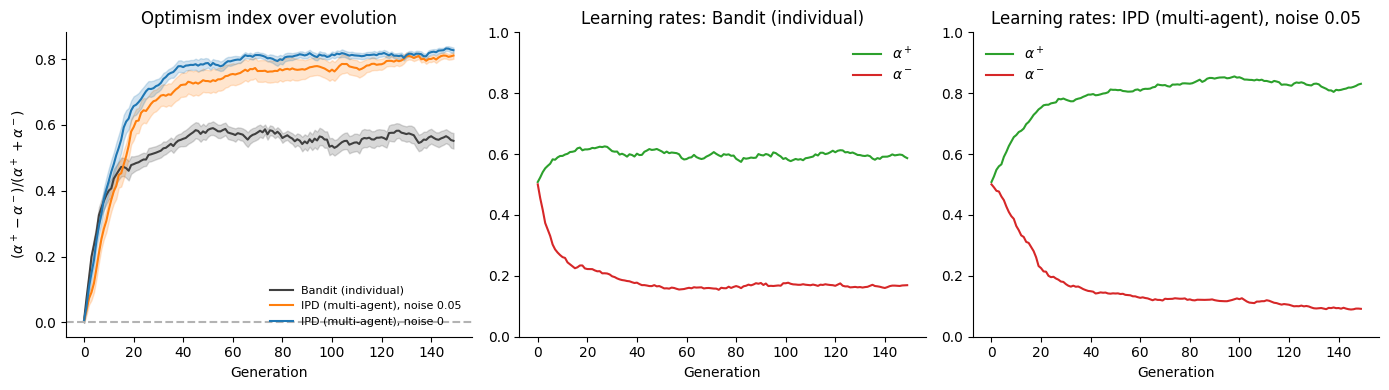

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for (label, out), c in zip(results.items(), ["0.25", "tab:orange", "tab:blue"]):
    m, se = out["bias"].mean(0), out["bias"].std(0) / np.sqrt(N_SEEDS)
    axes[0].plot(m, color=c, label=label)
    axes[0].fill_between(range(N_GEN), m - se, m + se, color=c, alpha=0.2)
axes[0].axhline(0, ls="--", c="0.7")
axes[0].set(title="Optimism index over evolution", xlabel="Generation",
            ylabel=r"$(\alpha^+ - \alpha^-)/(\alpha^+ + \alpha^-)$")
axes[0].legend(frameon=False, fontsize=8, loc="lower right")
for ax, (label, out) in zip(axes[1:], list(results.items())[:2]):
    ax.plot(out["a_pos"].mean(0), label=r"$\alpha^+$", color="tab:green")
    ax.plot(out["a_neg"].mean(0), label=r"$\alpha^-$", color="tab:red")
    ax.set(title=f"Learning rates: {label}", xlabel="Generation", ylim=(0, 1))
    ax.legend(frameon=False)
for ax in axes: ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig("figures/02_evolution.png", dpi=150); plt.show()